In [1]:

import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import seaborn as sns


In [2]:

digits = load_digits()

X = digits.data
y = digits.target

print("Dataset shape:", X.shape)
print("Target classes:", np.unique(y))


Dataset shape: (1797, 64)
Target classes: [0 1 2 3 4 5 6 7 8 9]


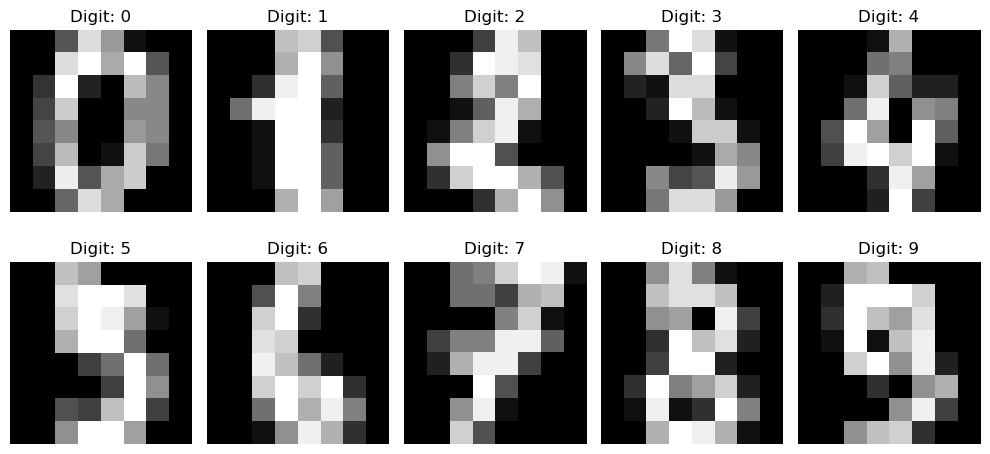

In [3]:

fig, axes = plt.subplots(2, 5, figsize=(10, 5))

for i, ax in enumerate(axes.flat):
    ax.imshow(digits.images[i], cmap="gray")
    ax.set_title(f"Digit: {digits.target[i]}")
    ax.axis("off")

plt.tight_layout()
plt.show()


In [4]:

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])


Training samples: 1437
Testing samples: 360


In [5]:

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)


In [6]:

svm = SVC(kernel="rbf", C=10, gamma="scale")

svm.fit(X_train, y_train)

print("SVM model trained successfully.")


SVM model trained successfully.


In [7]:

y_pred = svm.predict(X_test)

print("Actual digits:   ", y_test[:10])
print("Predicted digits:", y_pred[:10])


Actual digits:    [5 2 8 1 7 2 6 2 6 5]
Predicted digits: [5 2 8 1 7 2 6 2 6 5]


In [8]:

accuracy = accuracy_score(y_test, y_pred)

print("SVM Accuracy:", round(accuracy * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred))


SVM Accuracy: 98.06 %

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        36
           1       0.97      0.97      0.97        36
           2       1.00      1.00      1.00        35
           3       1.00      1.00      1.00        37
           4       0.95      0.97      0.96        36
           5       0.97      1.00      0.99        37
           6       0.97      1.00      0.99        36
           7       0.95      0.97      0.96        36
           8       1.00      0.94      0.97        35
           9       1.00      0.94      0.97        36

    accuracy                           0.98       360
   macro avg       0.98      0.98      0.98       360
weighted avg       0.98      0.98      0.98       360



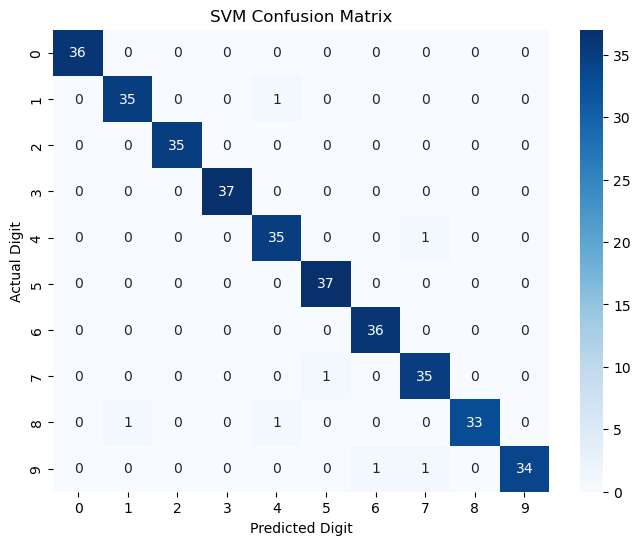

In [9]:

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")

plt.xlabel("Predicted Digit")
plt.ylabel("Actual Digit")
plt.title("SVM Confusion Matrix")
plt.show()


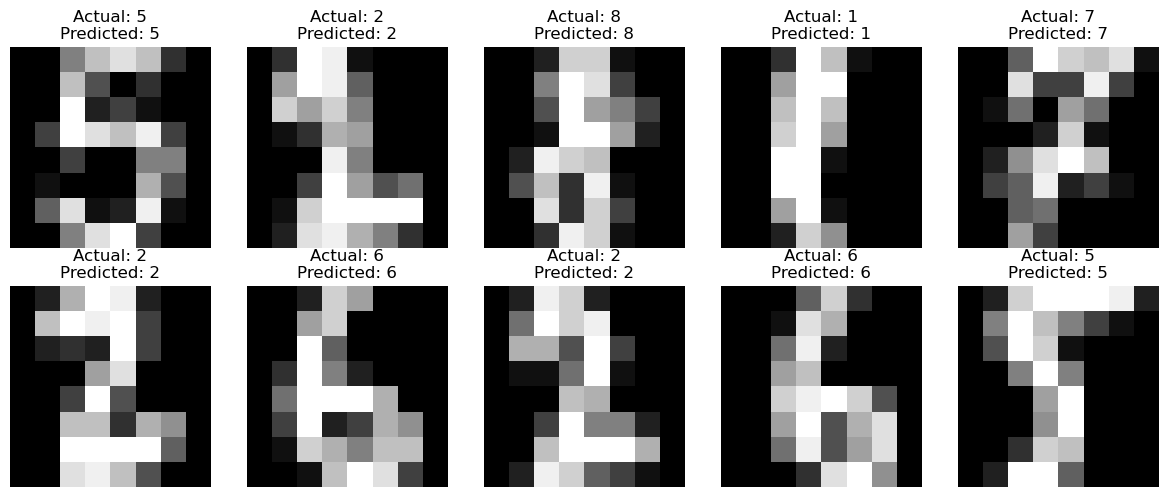

In [11]:

X_original = digits.data

X_train_original, X_test_original, y_train_original, y_test_original = train_test_split(
    X_original, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for i, ax in enumerate(axes.flat):
    ax.imshow(X_test_original[i].reshape(8, 8), cmap="gray")
    ax.set_title(f"Actual: {y_test[i]}\nPredicted: {y_pred[i]}")
    ax.axis("off")

plt.tight_layout()
plt.show()
